# Ablations: number of attention heads and context length

Notebook 04 compared position encodings, normalization, feed forward blocks and grouped query attention. This notebook adds the two remaining questions from the roadmap:

1. How many attention heads? The width stays at 128, so more heads means smaller heads (1 head of size 128, up to 8 heads of size 16).
2. How long a context? From 32 to 256 characters. The number of tokens per training step is held fixed at 4096, so a shorter context uses a bigger batch.

Everything else is the same LLaMA style model (RoPE, RMSNorm, SwiGLU, ordinary multi head attention), the same optimizer settings and number of steps, and the same validation text. Each setting is trained with two seeds. The model code comes from llama_gpt.py, the module used by the training script and the tests.

For the context experiment, validation loss is reported two ways. The all positions number averages over every position in a window, so a short window is penalized simply because its early positions have little context to look at. The last 32 positions number only scores the final 32 positions of each window, which is each model's best case.

In [1]:
import os, math, time, random, urllib.request
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from dataclasses import replace

from llama_gpt import Config, Model, CharData, get_lr

random.seed(0); np.random.seed(0); torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/input.txt"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", "data/input.txt")
data = CharData(open("data/input.txt", encoding="utf-8").read())
print("device:", device, "| vocab", data.vocab_size, "| train tokens", len(data.train), "| val tokens", len(data.val))

device: cpu | vocab 65 | train tokens 1003854 | val tokens 111540


In [2]:
TOKENS_PER_STEP = 4096
ITERS = 700
LR, MIN_LR, WARMUP = 2e-3, 2e-4, 50

@torch.no_grad()
def evaluate(model, batch_size, n_batches=40, tail=32):
    model.eval()
    g = torch.Generator().manual_seed(123)                     # the same validation windows for every run of a given block size
    bs = model.cfg.block_size
    all_pos, last_pos = 0.0, 0.0
    for _ in range(n_batches):
        x, y = data.get_batch("val", batch_size, bs, g, device)
        logits = model(x)[0]
        ce = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), reduction="none").view(y.shape)
        all_pos += ce.mean().item()
        last_pos += ce[:, -tail:].mean().item()
    model.train()
    return all_pos / n_batches, last_pos / n_batches

def fit(cfg, seed):
    torch.manual_seed(seed)
    model = Model(cfg).to(device).train()
    batch_size = TOKENS_PER_STEP // cfg.block_size
    decay = [p for p in model.parameters() if p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.dim() < 2]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": 0.1}, {"params": no_decay, "weight_decay": 0.0}], lr=LR, betas=(0.9, 0.99))
    g = torch.Generator().manual_seed(seed)
    curve = []
    t0 = time.time()
    for it in range(ITERS + 1):
        if it % 100 == 0 or it == ITERS:
            curve.append((it,) + evaluate(model, batch_size))
        if it == ITERS:
            break
        for gr in opt.param_groups:
            gr["lr"] = get_lr(it, LR, MIN_LR, WARMUP, ITERS)
        x, y = data.get_batch("train", batch_size, cfg.block_size, g, device)
        loss = model(x, y)[1]
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    return curve, time.time() - t0, model.num_params()

base = Config(block_size=128, vocab_size=data.vocab_size, n_layer=4, n_head=4, n_kv_head=4, n_embd=128, pos="rope", norm="rms", mlp="swiglu")
def mha(n_head, block):
    return replace(base, n_head=n_head, n_kv_head=n_head, block_size=block)

settings = {
    "heads=1 (size 128)": mha(1, 128),
    "heads=2 (size 64)": mha(2, 128),
    "heads=4 (size 32), context 128": mha(4, 128),       # the shared baseline
    "heads=8 (size 16)": mha(8, 128),
    "context 32": mha(4, 32),
    "context 64": mha(4, 64),
    "context 256": mha(4, 256),
}
SEEDS = (0, 1)
results = {}
for name, cfg in settings.items():
    runs = []
    for s in SEEDS:
        curve, secs, n = fit(cfg, s)
        runs.append((curve, secs, n))
        print(f"{name:32s} seed {s}: val all {curve[-1][1]:.4f} | last 32 {curve[-1][2]:.4f} | {secs:4.0f}s | {n:,} params")
    results[name] = runs

heads=1 (size 128)               seed 0: val all 1.6716 | last 32 1.6453 |  201s | 812,288 params


heads=1 (size 128)               seed 1: val all 1.6874 | last 32 1.6611 |  125s | 812,288 params


heads=2 (size 64)                seed 0: val all 1.6403 | last 32 1.6106 |  128s | 812,288 params


heads=2 (size 64)                seed 1: val all 1.6521 | last 32 1.6192 |  126s | 812,288 params


heads=4 (size 32), context 128   seed 0: val all 1.6357 | last 32 1.5991 |  131s | 812,288 params


heads=4 (size 32), context 128   seed 1: val all 1.6295 | last 32 1.5981 |  129s | 812,288 params


... (4 outputs left out)

context 64                       seed 0: val all 1.6273 | last 32 1.5908 |  124s | 812,288 params


context 64                       seed 1: val all 1.6285 | last 32 1.5912 |  126s | 812,288 params


context 256                      seed 0: val all 1.6277 | last 32 1.6070 |  145s | 812,288 params


context 256                      seed 1: val all 1.6334 | last 32 1.6223 |  146s | 812,288 params


## Results

number of heads (context 128)
setting                             params  all pos (mean)      min      max  last 32 (mean)  sec/run
heads=1 (size 128)                 812,288          1.6795   1.6716   1.6874          1.6532      163
heads=2 (size 64)                  812,288          1.6462   1.6403   1.6521          1.6149      127
heads=4 (size 32), context 128     812,288          1.6326   1.6295   1.6357          1.5986      130
heads=8 (size 16)                  812,288          1.6346   1.6327   1.6365          1.6006      140

context length (4 heads, 4096 tokens per step)
setting                             params  all pos (mean)      min      max  last 32 (mean)  sec/run
context 32                         812,288          1.6724   1.6681   1.6767          1.6724      121
context 64                         812,288          1.6279   1.6273   1.6285          1.5910      125
heads=4 (size 32), context 128     812,288          1.6326   1.6295   1.6357          1.5986      130
cont

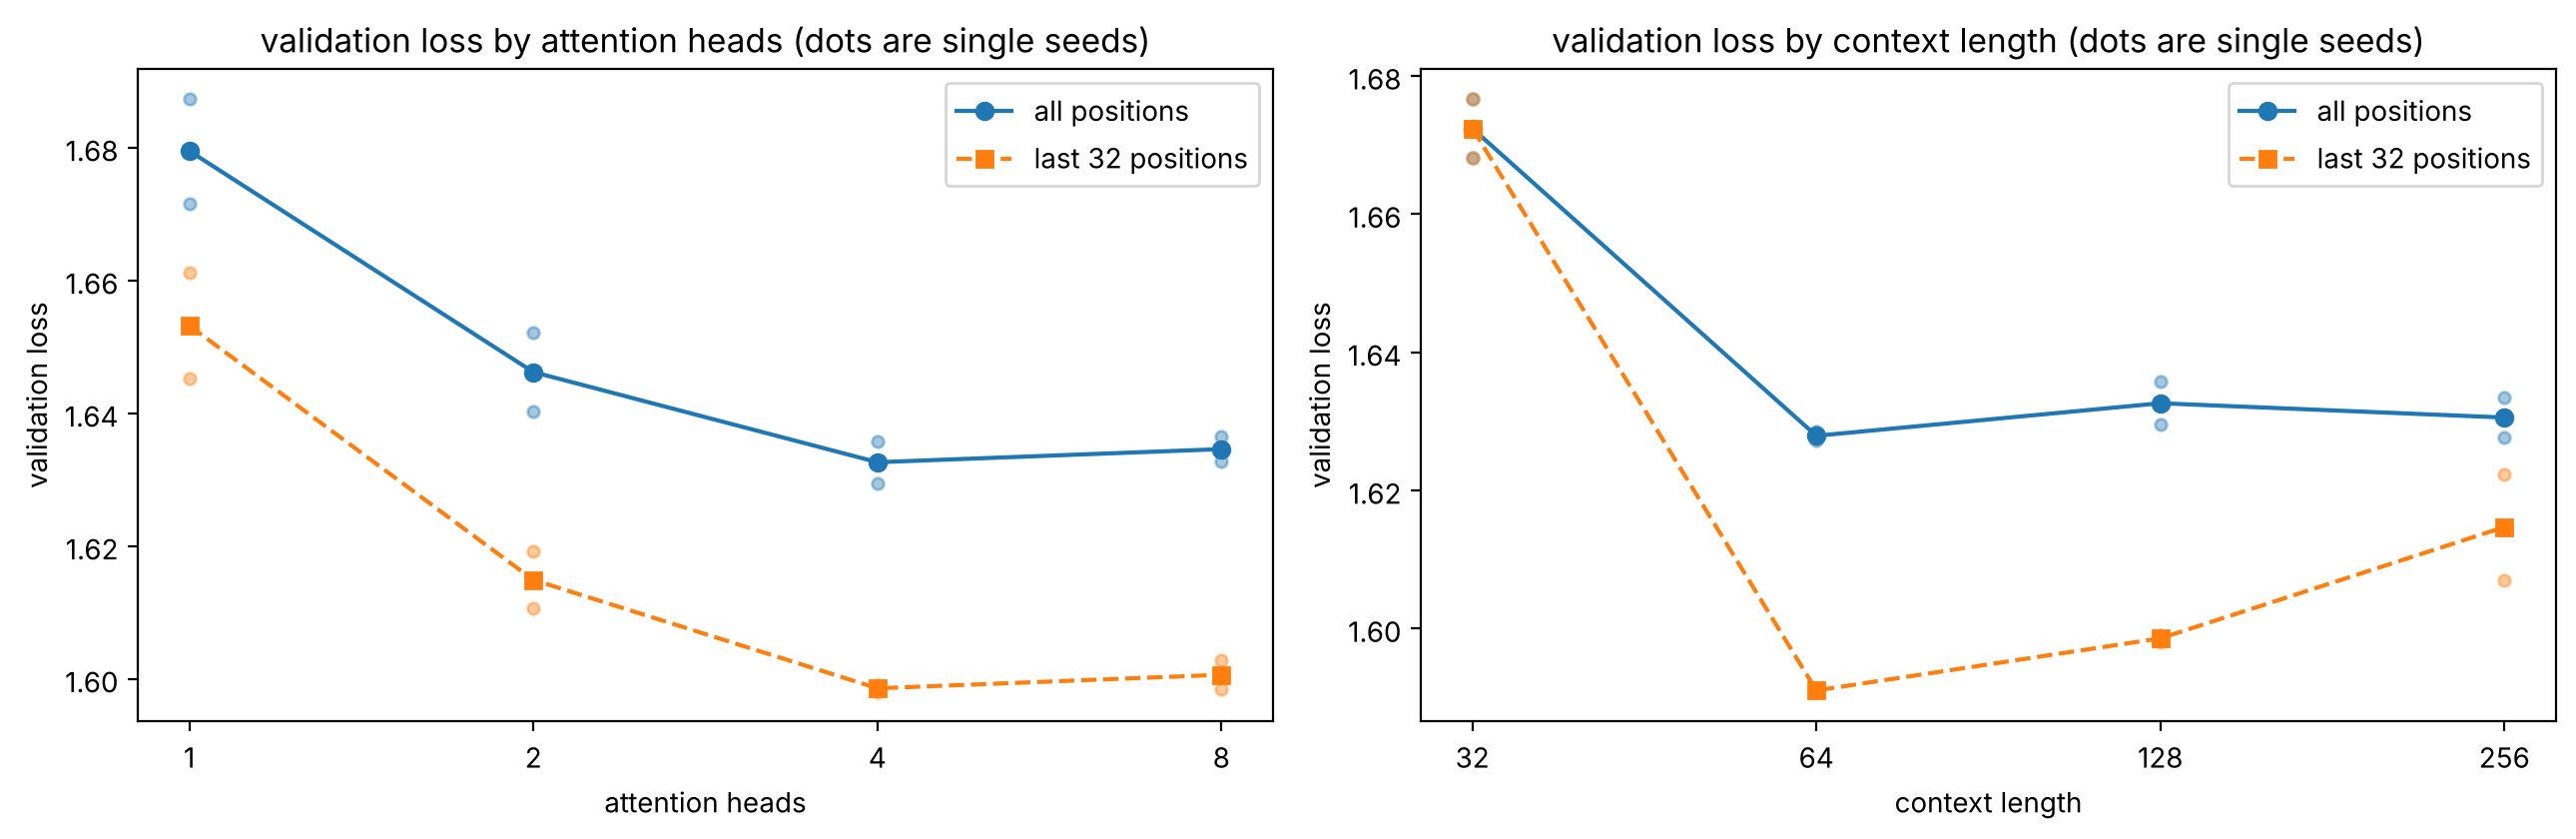

In [3]:
def summarize(names):
    print(f"{'setting':32s} {'params':>9s} {'all pos (mean)':>15s} {'min':>8s} {'max':>8s} {'last 32 (mean)':>15s} {'sec/run':>8s}")
    for name in names:
        runs = results[name]
        a = [r[0][-1][1] for r in runs]; b = [r[0][-1][2] for r in runs]
        print(f"{name:32s} {runs[0][2]:9,d} {np.mean(a):15.4f} {min(a):8.4f} {max(a):8.4f} {np.mean(b):15.4f} {np.mean([r[1] for r in runs]):8.0f}")

head_names = ["heads=1 (size 128)", "heads=2 (size 64)", "heads=4 (size 32), context 128", "heads=8 (size 16)"]
ctx_names = ["context 32", "context 64", "heads=4 (size 32), context 128", "context 256"]
print("number of heads (context 128)"); summarize(head_names)
print("\ncontext length (4 heads, 4096 tokens per step)"); summarize(ctx_names)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for names, a, title, labels in ((head_names, ax[0], "attention heads", [1, 2, 4, 8]), (ctx_names, ax[1], "context length", [32, 64, 128, 256])):
    m_all = [np.mean([r[0][-1][1] for r in results[n]]) for n in names]
    m_last = [np.mean([r[0][-1][2] for r in results[n]]) for n in names]
    for n_idx, n in enumerate(names):
        a.scatter([n_idx] * len(SEEDS), [r[0][-1][1] for r in results[n]], color="C0", alpha=0.4, s=18)
        a.scatter([n_idx] * len(SEEDS), [r[0][-1][2] for r in results[n]], color="C1", alpha=0.4, s=18)
    a.plot(range(4), m_all, "o-", color="C0", label="all positions")
    a.plot(range(4), m_last, "s--", color="C1", label="last 32 positions")
    a.set_xticks(range(4)); a.set_xticklabels(labels); a.set_xlabel(title); a.set_ylabel("validation loss"); a.legend(); a.set_title(f"validation loss by {title} (dots are single seeds)")
plt.tight_layout(); plt.show()

Checks on the experiment itself: every run really learned, the baseline run is the same configuration in both tables, and the context sweep used the same number of tokens per step.

In [4]:
for name, runs in results.items():
    for curve, _, _ in runs:
        assert curve[-1][1] < curve[0][1] - 1.0 and all(math.isfinite(v) for c in curve for v in c), name
assert settings["heads=4 (size 32), context 128"] == base
assert {n: TOKENS_PER_STEP // c.block_size * c.block_size for n, c in settings.items()} == {n: TOKENS_PER_STEP for n in settings}
# the two seeds should agree on the sign of every large effect, otherwise the effect is not trustworthy
print("all runs learned; baseline shared between tables; tokens per step identical across runs")

all runs learned; baseline shared between tables; tokens per step identical across runs


## Findings

Number of heads. One head is clearly worse than the others: validation loss 1.680 against 1.633 for four heads, and the two seeds of each setting differ by less than 0.02. Two heads sit in between (1.646). Four and eight heads are the same within noise (1.633 and 1.635). At this width, a handful of heads is enough, and past four there is nothing to gain.

Context length. A context of 32 characters is clearly worse (1.672). Contexts of 64, 128 and 256 are the same within noise on the all positions number (1.628, 1.633, 1.631). On the last 32 positions number the 256 context is slightly worse (1.615 against 1.591 for 64), which is a sign that with only 700 steps and a fixed number of tokens per step, the model has not learned to use a long context, and the longer windows mean fewer sequences per step. Whether longer context helps with more training is not answered by this experiment.

Limits. One dataset of about 1 MB, two seeds, 700 steps, one model width. Differences below roughly 0.01 should be treated as noise, since the seed spread alone is up to 0.02 for some settings.